In [117]:
%pip install --upgrade pip
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Hosting Capacity IEEE 37 barras (OpenDSS)

## Configuração geral
* Modo: `set mode=daily number=24 stepsize=1h`
* Verbose ligado, plotar tensões em pu
* Limites de tensão (PRODIST): 0,93 a 1,05 pu
* Sobrecarga: corrente acima da `normamps` de linhas e kVA acima do nominal dos trafos

## Dimensionamento do PV
* Soma das cargas de pico: 2457 kW
* 8 PVSystems x pmpp 307,125 kW = 2457 kW instalado
* kva do inversor: 340 por unidade
* Barras: 728, 733, 737, 740, 718, 720, 722, 742 

## Cenários da Parte I
| # | PV | loadmult | Detalhes |
|---|---|---|
| 1 | Não | 1.0 |
| 2 | Não | 0.2 |
| 3 | Sim | 0.2 |
| 4 | Sim | 1.0 |
| 5 | Sim | 1.0 | aumenta pmpp ate cair

## Métricas por cenário
* Sobretensão e subtensão por barra (nome da barra + pu)
* Sobrecarga em linhas e transformadores
* Fluxo reverso (potência negativa na subestação / início do alimentador)
* Perdas totais (kW e %)

## Lógica de tensão
1. Para cada barra, agrupar as 3 fases
2. Pegar min e max entre as fases por barra
3. Retornar nome da barra e pu
4. Plotar máximas e mínimas 

## Parte II: armazenamento
* BESS central: 1 unidade grande, perto da subestação ou do maior PV
* BESS distribuído: várias unidades menores nas barras com PV
* Mesma energia total nas duas abordagens, para comparar justo
* Comparar tensão, perdas, fluxo reverso e sobrecarga

## Parte III: microrrede e ilhamento
* Definir qual trecho do circuito vira a microrrede e onde fica o ponto de abertura
* Ilhamento com BESS central e com BESS distribuído
* Cenários de ilhamento: dia vs noite, carga pico vs 20%, com e sem PV
* Métrica: tempo de sobrevivência (horas até o BESS esgotar ou a tensão sair do limite)

## Corte de carga
* Dividir cargas em industriais e residenciais
* Definir prioridade de corte (ex: industrial não crítica primeiro, depois residencial)
* Cortar em etapas e medir quanto o tempo de sobrevivência aumenta em cada etapa
* Comparar sobrevivência com e sem corte

## Curvas 

New LoadShape.LS_Resid npts=24 interval=1 mult=[0.45 0.40 0.37 0.35 0.35 0.40 0.55 0.65 0.60 0.50 0.45 0.45 0.50 0.48 0.45 0.45 0.50 0.65 0.85 0.95 1.00 0.95 0.80 0.60]

New LoadShape.LS_Ind npts=24 interval=1 mult=[0.30 0.28 0.27 0.27 0.30 0.35 0.50 0.70 0.88 0.95 1.00 1.00 0.90 0.95 1.00 0.98 0.92 0.80 0.65 0.50 0.42 0.38 0.34 0.32]

New loadshape.Irrad npts=24 interval=1 mult=[0 0 0 0 0 0 .1 .2 .3 .5 .8 .9 1.0 1.0 .99 .9 .7 .4 .1 0 0 0 0 0]

New Tshape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]

New XYcurve.Effic npts=4 xarray=[.1 .2 .4 1] yarray=[0.86 .9 .93 .97]

New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1 .8 .6]



In [118]:
import numpy as np    #np, mpl and pd serve as a nicknames
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import os
import dss #OpenDss Module

parte 1 

In [119]:
os.chdir('C:\\Users\\amy\\Desktop\\934\\')   # force going to the working folder (ADJUST FOR YOUR OWN PATH!)
mydir=os.getcwd()                          # mydir stores the working path
print(mydir)                               # just to check if things worked out

C:\Users\amy\Desktop\934


In [120]:
dss_engine = dss.DSS
DSSText = dss_engine.Text
DSSCircuit = dss_engine.ActiveCircuit
DSSSolution = dss_engine.ActiveCircuit.Solution
ControlQueue = dss_engine.ActiveCircuit.CtrlQueue

In [121]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'
Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

In [122]:
# Get all element names and store in variant array of strings
Elenames = DSSCircuit.AllElementNames
print('List of elements')
print ('Total:' +  str(len(Elenames)))
print(Elenames)

# Get all load names and store in variant array of strings
Loadnames = DSSCircuit.Loads.AllNames
print('List of Loads')
print ('Total:' +  str(len(Loadnames)))
print(Loadnames)

# Get all bus names and store in variant array of strings
Busnames = DSSCircuit.AllBusNames
print('List of Buses')
print ('Total:' +  str(len(Busnames)))
print(Busnames)

# Get all transformers names and store in variant array of strings
Trafonames = DSSCircuit.Transformers.AllNames
print('List of Transformers')
print ('Total:' +  str(len(Trafonames)))
print(Trafonames)

# Get all line names and store in variant array of strings
Linenames = DSSCircuit.Lines.AllNames
print('List of Lines')
print ('Total:' +  str(len(Linenames)))
print(Linenames)

List of elements
Total:73
['Vsource.source', 'Transformer.subxf', 'Transformer.xfm1', 'Line.l1', 'Line.l2', 'Line.l3', 'Line.l4', 'Line.l5', 'Line.l6', 'Line.l7', 'Line.l8', 'Line.l9', 'Line.l10', 'Line.l11', 'Line.l12', 'Line.l13', 'Line.l14', 'Line.l15', 'Line.l16', 'Line.l17', 'Line.l18', 'Line.l19', 'Line.l20', 'Line.l21', 'Line.l22', 'Line.l23', 'Line.l24', 'Line.l25', 'Line.l26', 'Line.l27', 'Line.l28', 'Line.l29', 'Line.l30', 'Line.l31', 'Line.l32', 'Line.l33', 'Line.l34', 'Line.l35', 'Transformer.reg1a', 'RegControl.creg1a', 'Transformer.reg1c', 'RegControl.creg1c', 'Line.jumper', 'Load.s701a', 'Load.s701b', 'Load.s701c', 'Load.s712c', 'Load.s713c', 'Load.s714a', 'Load.s714b', 'Load.s718a', 'Load.s720c', 'Load.s722b', 'Load.s722c', 'Load.s724b', 'Load.s725b', 'Load.s727c', 'Load.s728', 'Load.s729a', 'Load.s730c', 'Load.s731b', 'Load.s732c', 'Load.s733a', 'Load.s734c', 'Load.s735c', 'Load.s736b', 'Load.s737a', 'Load.s738a', 'Load.s740c', 'Load.s741c', 'Load.s742a', 'Load.s742b',

#Cenario um, caso base, sem pv, loadmult = 1 

In [123]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

#Configure power flow options
DSSText.Command = 'reset'
#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=24'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI'

DSSSolution.Solve()#Solve power flow

#resultados do caso base

In [116]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -1235.344 kW
Total kVAr delivered to the network: -665.306 kvar
Total active losses: 35.177 kW
Percent losses: 2.848%
Total reactive losses: 79.841 kVAr


#verificando limites operativos dos elementos (overloads e sub e sobretensoes)

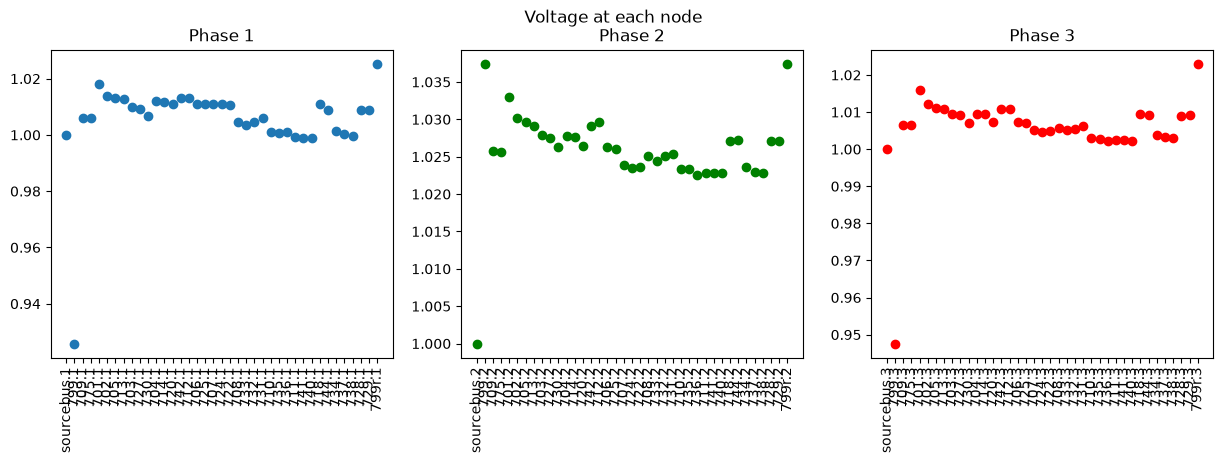

In [109]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

# Transformers AMPS loading 


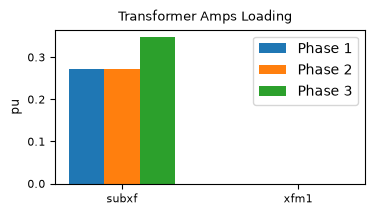

In [110]:
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

#**************--------------Lines Amps Loading


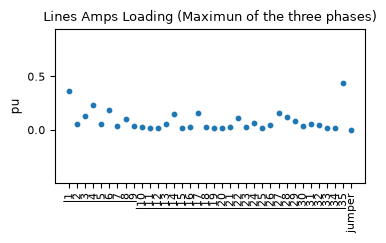

In [111]:
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()

In [112]:
Load_kW = np.zeros((len(Loadnames), 24))
Load_kvar = np.zeros((len(Loadnames), 24))

for h in range(24):
    DSSSolution.SolveSnap()   # ou o Solve que você usa no loop
    for i, load in enumerate(Loadnames):
        DSSCircuit.SetActiveElement('load.%s' % load)
        p = DSSCircuit.ActiveElement.Powers   # [P1, Q1, P2, Q2, ...]
        Load_kW[i, h] = sum(p[0::2])
        Load_kvar[i, h] = sum(p[1::2])

Results for load power


In [124]:
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

plots load power

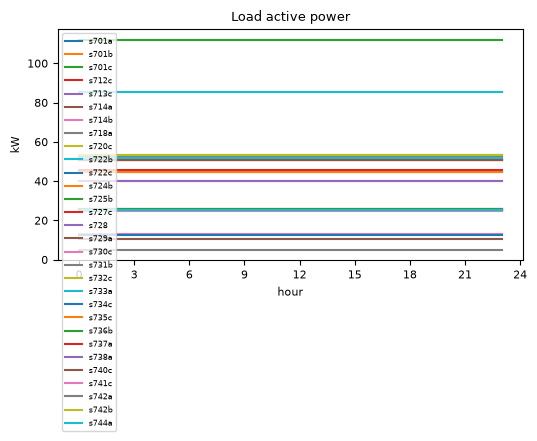

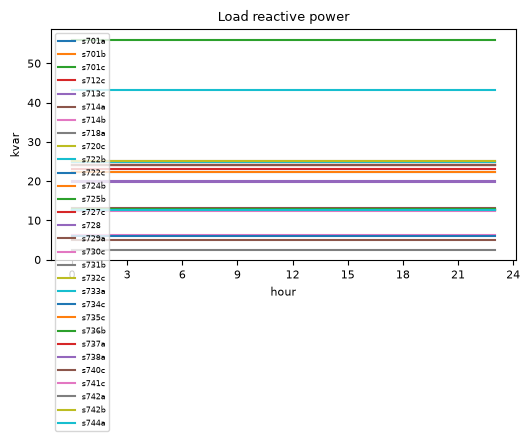

In [125]:
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [126]:
#DSSText.Command = 'New energyemeter.substation buses=799r.1.2.3 terminal=1'
dss

DSSException: (#263) New Command: Object Type "energyemeter" not found. 
New energyemeter.substation buses=799r.1.2.3 terminal=1 

NameError: name 'Total_Act_Power' is not defined

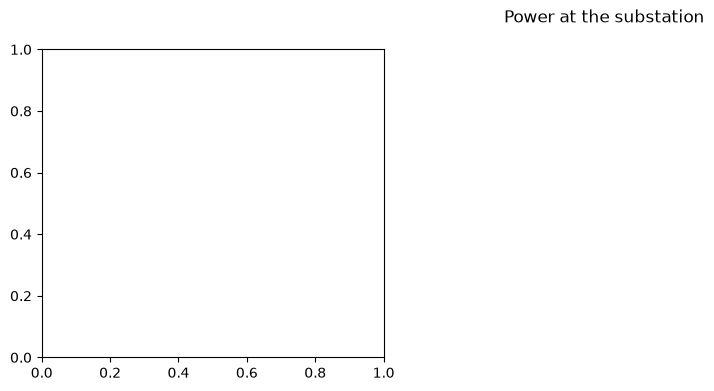

In [114]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

cenario 2 - Loads with 20% of peak value  power flow, with no PV

In [131]:
DSSText.Command = 'reset'


In [132]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

In [133]:
DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

In [134]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [135]:
#Configure power flow options
DSSText.Command = 'set loadmult = 0.2'
#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=24'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI' 

DSSSolution.Solve() #Solve power flow

#resultados do caso sem pv e loadmult 02

In [136]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)

Total kW delivered to the network: -241.499 kW
Total kVAr delivered to the network: -113.520 kvar
Total active losses: 1.321 kW
Percent losses: 0.547%
Total reactive losses: -3.687 kVAr


#verificando limites operativos dos elementos (overloads e sub e sobretensoes)

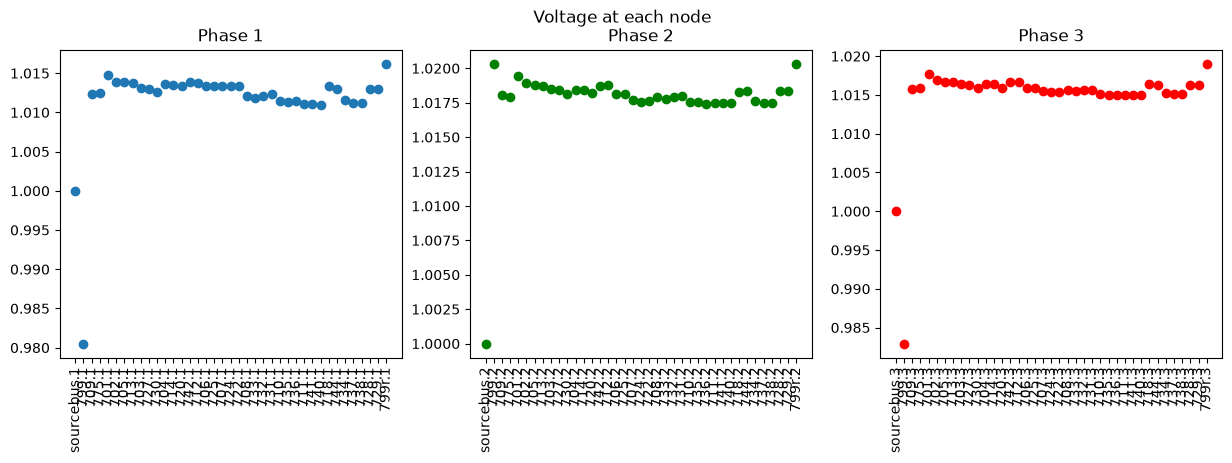

In [ ]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

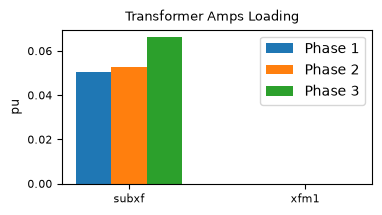

In [ ]:
# Transformers AMPS loading 
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()

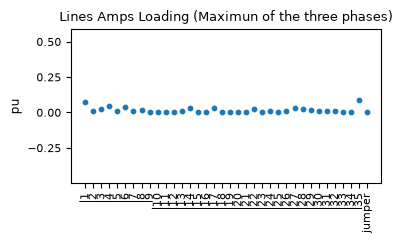

In [137]:
#**************--------------Lines Amps Loading
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()

resolts fopr load power

In [ ]:
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)


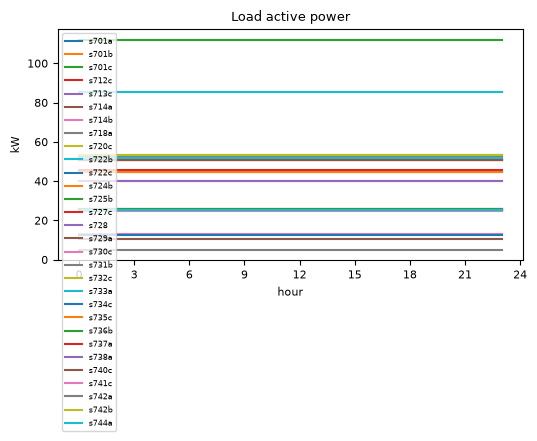

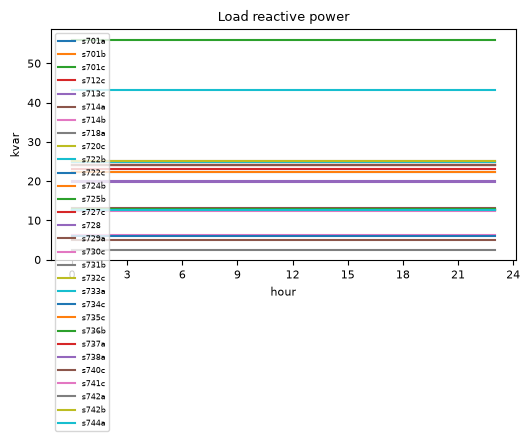

In [ ]:

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

#*******---------Results for the substation


NameError: name 'Total_Act_Power' is not defined

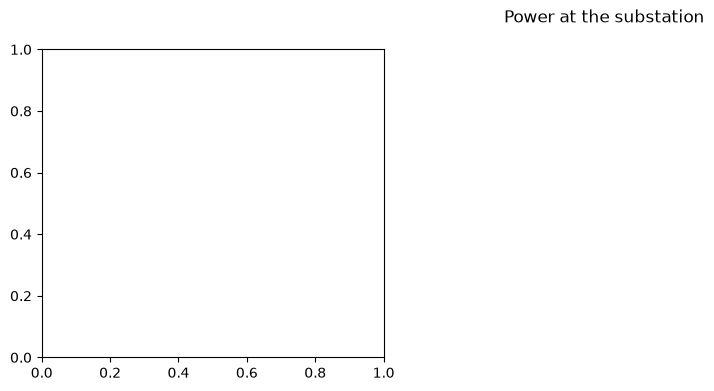

In [ ]:

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

parte 1 Scenario 3 - Loads with  peak value and PV generation


In [142]:
#Load the circuit model
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

#Get list of elements
Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'


#Define curves fo the PV System: Temperature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYCurve.TempxP npts=4 xarray=[0 25 75 100] yarray=[1.2 1.0 0.8 0.6]'
DSSText.Command = 'New XYCurve.PxEff npts=4 xarray=[.1 .2 .4 1.0] yarray=[.86 .9 .93 1]'

#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '






DSSException: (#401) PVSystem.pv_1.TDaily: TShape object "Temp" not found.

In [141]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [139]:
#Configure power flow options
DSSText.Command = 'set loadmult = 1'
DSSText.Command = 'reset'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=24'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI' 

DSSSolution.Solve() #Solve power flow

#resultados do caso 

In [140]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)


Total kW delivered to the network: -1235.336 kW
Total kVAr delivered to the network: -665.302 kvar
Total active losses: 35.177 kW
Percent losses: 2.848%
Total reactive losses: 79.840 kVAr


In [ ]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

In [ ]:
# Transformers AMPS loading 
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()


In [ ]:
#**************--------------Lines Amps Loading
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()


In [ ]:
#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()

In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

cenario 4 - Loads with 20% of peak value  power flow, with  PV

In [ ]:
#Load the circuit model
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

#Get list of elements
Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'


#Define curves fo the PV System: Temperature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New XYCurve.TempxP npts=4 xarray=[0 25 75 100] yarray=[1.2 1.0 0.8 0.6]'
DSSText.Command = 'New XYCurve.PxEff npts=4 xarray=[.1 .2 .4 1.0] yarray=[.86 .9 .93 1]'

#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '



In [ ]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

#Configure power flow options and solving


In [ ]:
DSSText.Command = 'set loadmult = 0.2'
DSSText.Command = 'reset'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=24'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI' 

DSSSolution.Solve() #Solve power flow

#resultados do caso 


In [ ]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)


In [ ]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

In [ ]:
# Transformers AMPS loading 
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()


In [ ]:
#**************--------------Lines Amps Loading
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()


cenario 5, indo com pv no maximo

In [ ]:
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'
Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

In [ ]:
DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'

In [ ]:
# industriais (os outros são residenciais), em minúsculo
ind_loads = ['s701a', 's701b', 's701c', 's728', 's737a', 's738a']

resd_profile = [0.45, 0.40, 0.37, 0.35, 0.35, 0.40, 0.55, 0.65, 0.60, 0.50, 0.45, 0.45,
                0.50, 0.48, 0.45, 0.45, 0.50, 0.65, 0.85, 0.95, 1.00, 0.95, 0.80, 0.60]

ind_profile = [0.30, 0.28, 0.27, 0.27, 0.30, 0.35, 0.50, 0.70, 0.88, 0.95, 1.00, 1.00,
               0.90, 0.95, 1.00, 0.98, 0.92, 0.80, 0.65, 0.50, 0.42, 0.38, 0.34, 0.32]

# Criar os loadshapes
DSSCircuit.LoadShapes.New('resd_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = resd_profile

DSSCircuit.LoadShapes.New('ind_loadshape')
DSSCircuit.LoadShapes.Npts = 24
DSSCircuit.LoadShapes.HrInterval = 1
DSSCircuit.LoadShapes.Pmult = ind_profile

# Atribuir aos loads
for load in Loadnames:
    DSSCircuit.SetActiveElement('load.%s' % load)
    if load.lower() in ind_loads:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'ind_loadshape'
    else:
        DSSCircuit.ActiveElement.Properties('daily').Val = 'resd_loadshape'

In [ ]:
#Load the circuit model
DSSText.Command = 'Compile ' + mydir + '/ieee37.dss'

#Get list of elements
Elenames = DSSCircuit.AllElementNames
Loadnames = DSSCircuit.Loads.AllNames
Busnames = DSSCircuit.AllBusNames
Trafonames = DSSCircuit.Transformers.AllNames
Linenames = DSSCircuit.Lines.AllNames

DSSText.Command = 'set normvminpu=0.93'
DSSText.Command = 'set normvmaxpu=1.05'


#Define curves fo the PV System: Temperature x Output Power(pu) and Output Power(pu) x Inversor efficiency
#(there is no irradiance curce because it won´t be a daily simulation)
DSSText.Command = 'New LoadShape.Irrad npts=24 interval=1 mult=[0 0 0 0 0 0 .10 .30 .50 .70 .85 .95 1.0 .95 .85 .60 .35 .10 0 0 0 0 0]'

DSSText.Command = 'New TShape.Temp npts=24 interval=1 temp=[25 25 25 25 25 25 25 25 35 40 45 50 60 60 55 40 35 30 25 25 25 25 25 25]'

DSSText.Command = 'New XYCurve.Effic npts=4 xarray=[.1 .2 .4 1.0] yarray=[.86 .90 .93 .97]'

DSSText.Command = 'New XYcurve.PvsT npts=4 xarray=[0 25 75 100] yarray=[1.2 1.0 .8 .6]'

#Install the PV System (no transformer will be used to connect the system to the bus)


DSSText.Command = 'New PVSystem.PV_1 phases=3 bus1=728.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_2 phases=3 bus1=733.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_3 phases=3 bus1=737.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_4 phases=3 bus1=740.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_5 phases=3 bus1=718.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_6 phases=3 bus1=720.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_7 phases=3 bus1=722.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '
DSSText.Command = 'New PVSystem.PV_8 phases=3 bus1=742.1.2.3 kv=4.8 conn=delta irrad=1.0 pmpp=307.125 kva=340 temperature=25 pf=1 %cutin=0.05 %cutout=0.05 effcurve=Effic P-tcurve=PvsT Daily=Irrad Tdaily=Temp '



In [ ]:
#Configure power flow options
DSSText.Command = 'set loadmult = 0.2'
DSSText.Command = 'reset'
#DSSText.Command = 'set controlmode=static'
DSSText.Command = 'set mode=daily'
DSSText.Command = 'set number=24'
DSSText.Command = 'set steps=1h'
DSSText.Command = 'set DemandInterval=true'
DSSText.Command = 'set overloadreport=true'
DSSText.Command = 'set voltexceptionreport=true'
DSSText.Command = 'set DIVerbose=true'
DSSText.Command = 'closeDI' 

DSSSolution.Solve() #Solve power flow

#resultados do caso 


In [ ]:
#Power and Losses
kW_BC = DSSCircuit.TotalPower[0] #in kW
kvar_BC = DSSCircuit.TotalPower[1] #in kVAr
kW_Loss_BC = DSSCircuit.Losses[0]/1000 #property returns values in W, here stored in kW
kvar_Loss_BC = DSSCircuit.Losses[1]/1000 #property returns values in VAr, here stored in kVAr
print("Total kW delivered to the network: %.3f kW" %kW_BC)
print("Total kVAr delivered to the network: %.3f kvar" %kvar_BC)
print("Total active losses: %.3f kW" %kW_Loss_BC)
print("Percent losses: %.3f" %abs(((kW_Loss_BC/kW_BC)*100)) + "%")
print("Total reactive losses: %.3f kVAr" %kvar_Loss_BC)


Total kW delivered to the network: -499.328 kW
Total kVAr delivered to the network: -248.592 kvar
Total active losses: 5.454 kW
Percent losses: 1.092%
Total reactive losses: 6.803 kVAr


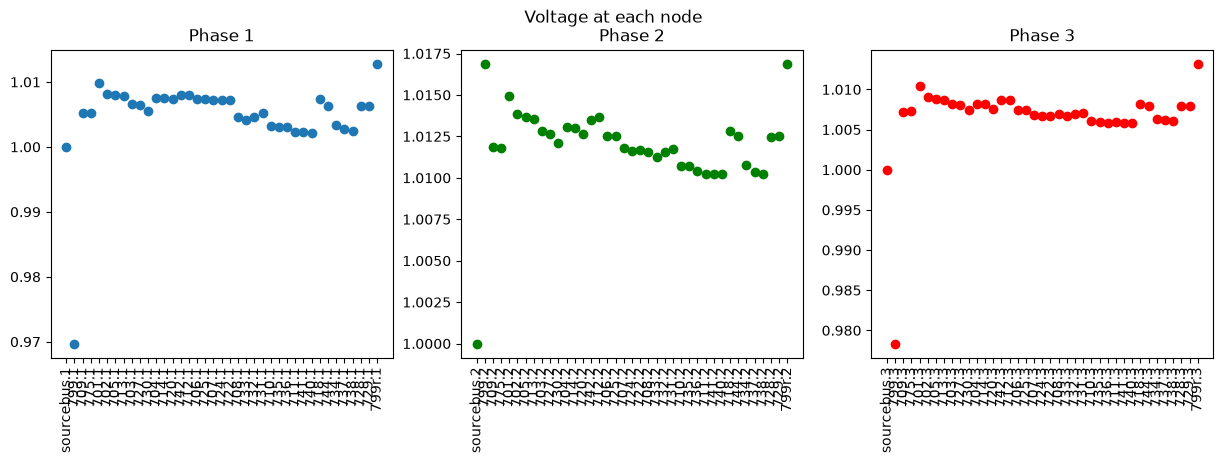

In [ ]:
#Voltage
# DSSCircuit.AllNodeVmagPUByPhase: gets per unit line-ground voltage magnitudes for each Bus 
#(same order as returned by DSSCircuit.AllNodeNamesByPhase)
nodesA_filtered = []
busVpuA_BC_filtered = []
nodesB_filtered = []
busVpuB_BC_filtered = []
nodesC_filtered = []
busVpuC_BC_filtered = []

busVpuA_BC=(DSSCircuit.AllNodeVmagPUByPhase(1))#phase 1
nodesA=(DSSCircuit.AllNodeNamesByPhase(1))#phase 1
for node, voltage in zip(nodesA, busVpuA_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesA_filtered.append(node)
        busVpuA_BC_filtered.append(voltage)
        
busVpuB_BC=(DSSCircuit.AllNodeVmagPUByPhase(2))#phase 2
nodesB=(DSSCircuit.AllNodeNamesByPhase(2))#phase 2
for node, voltage in zip(nodesB, busVpuB_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesB_filtered.append(node)
        busVpuB_BC_filtered.append(voltage)
        
busVpuC_BC=(DSSCircuit.AllNodeVmagPUByPhase(3))#phase 3
nodesC=(DSSCircuit.AllNodeNamesByPhase(3))#phase 3
for node, voltage in zip(nodesC, busVpuC_BC):#remove voltage regulators
    if not node.startswith("reg"):
        nodesC_filtered.append(node)
        busVpuC_BC_filtered.append(voltage)

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Voltage at each node')
         
plt.subplot(1,3,1)
plt.title('Phase 1')
plt.scatter(nodesA_filtered,busVpuA_BC_filtered)
plt.xticks(rotation=90)

plt.subplot(1,3,2)
plt.title('Phase 2')
plt.scatter(nodesB_filtered,busVpuB_BC_filtered,color='g')
plt.xticks(rotation=90)

plt.subplot(1,3,3)
plt.title('Phase 3')
plt.scatter(nodesC_filtered,busVpuC_BC_filtered, color='r')
plt.xticks(rotation=90)

plt.show()

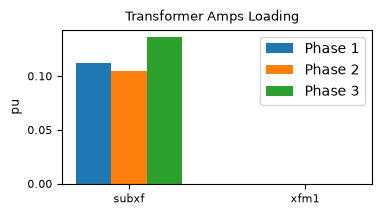

In [ ]:
# Transformers AMPS loading 
#This function gets transformer current data:all phases current magnitude at HV(wdg1) side winding,
# all phases Amps loading at HV side 

#List of transformers (excluding the voltage regulators)
onlytrafo = [trafo for trafo in Trafonames if not trafo.startswith('reg')]

#Initialize variables
All_Wdg_Amp = np.zeros((len(onlytrafo),24))#to store all phases winding currents at HV and LV sides in complex form (24 entries for each three phase transformer)
Transf_Wdg1_Amps = np.zeros((len(onlytrafo),3))#to store all phases current magnitude at HV side winding )   
Transf_Amps_loading = np.zeros((len(onlytrafo),3))#to store all phases Amps loading at HV side 
Transf_Max_Amps_loading = np.zeros((len(onlytrafo)))#to store maximun amps loading at HV side (the maximun of the three phases)       
#------------------------------
for itrafo, trafo in enumerate(onlytrafo):
          DSSCircuit.SetActiveElement('Transformer.%s' %(trafo))
          DSSCircuit.Transformers.Name = trafo
          DSSCircuit.Transformers.Wdg = 1
          amp_rate = DSSCircuit.ActiveElement.NormalAmps#get Normal ampere rating (OpenDSS defines it for Winding 1)
          All_Wdg_Amp[itrafo,:] = DSSCircuit.Transformers.WdgCurrents#get all winding currents at HV and LV sides in complex form  
          Transf_Wdg1_Amps[itrafo,0]=(np.sqrt(All_Wdg_Amp[itrafo,0]**2+All_Wdg_Amp[itrafo,1]**2))#HV side Wdg current , phase 1
          Transf_Wdg1_Amps[itrafo,1]=(np.sqrt(All_Wdg_Amp[itrafo,8]**2+All_Wdg_Amp[itrafo,9]**2)) #HV side Wdg current , phase 2
          Transf_Wdg1_Amps[itrafo,2]=(np.sqrt(All_Wdg_Amp[itrafo,16]**2+All_Wdg_Amp[itrafo,17]**2))#HV side Wdg current , phase 3
    
          Transf_Amps_loading[itrafo,0]=Transf_Wdg1_Amps[itrafo,0]/amp_rate #HV side Wdg current loading, phase 1 
          Transf_Amps_loading[itrafo,1]=Transf_Wdg1_Amps[itrafo,1]/amp_rate #HV side Wdg current loading, phase 2
          Transf_Amps_loading[itrafo,2]=Transf_Wdg1_Amps[itrafo,2]/amp_rate #HV side Wdg current loading, phase 3

#Create figure
plt.figure(figsize=(4,2))
plt.suptitle('Transformer Amps Loading',fontsize=9)

X = range(0,len(onlytrafo))#0 1 2 3 ... len(onlytrafo)-1
X = np.array(X) 
bar_width = 0.2

plt.bar(X - bar_width,Transf_Amps_loading[:,0],width=bar_width, label='Phase 1')
plt.bar(X,Transf_Amps_loading[:,1],width=bar_width, label='Phase 2')
plt.bar(X +  bar_width,Transf_Amps_loading[:,2],width=bar_width, label='Phase 3')
plt.xticks(X, onlytrafo)
plt.ylabel("pu",fontsize="small")
plt.legend(fontsize=4)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend()
plt.show()


In [ ]:
#**************--------------Lines Amps Loading
Line_Max_Amp = np.zeros((len(Linenames)))
for iline, line in enumerate(Linenames):
        DSSCircuit.SetActiveElement('line.%s' %(line))
        amp_rate = DSSCircuit.ActiveElement.NormalAmps
        Line_Max_Amp[iline] = max(DSSCircuit.ActiveElement.CurrentsMagAng[0:12:2])/amp_rate

#Creat e figure
plt.figure(figsize=(4,2))
plt.title('Lines Amps Loading (Maximun of the three phases)',fontsize=9)
plt.scatter(Linenames,Line_Max_Amp, s=10)
plt.ylabel("pu",fontsize="small")
plt.xticks(rotation=90)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.ylim(min(Line_Max_Amp)-0.5, max(Line_Max_Amp) + 0.5)
plt.show()


In [ ]:
#*******---------Results for the substation

#Create figure
plt.figure(figsize=(15,4))
plt.suptitle('Power at the substation')

#Active power
plt.subplot(1,3,1)
plt.plot(Total_Act_Power)
plt.title('Circuit active power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Reactive power
plt.subplot(1,3,2)
plt.plot(Total_React_Power)
plt.title('Circuit reactive power',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

#Losses
# Calculate the percentage of total active losses to total active power
percentage_losses = [abs(loss / power) * 100 for loss, power in zip(Total_Act_Losses, Total_Act_Power)]

plt.subplot(1,3,3)
plt.plot(percentage_losses)
plt.title('Circuit total active losses',fontsize=9)
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("%",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

plt.show()

In [ ]:
#*******------Results for load power
#each dataframe has a column associated with each load and 24 lines
dfLoad_kW = pd.DataFrame(np.vstack(Load_kW[:,:].T),columns=Loadnames)
dfLoad_kvar = pd.DataFrame(np.vstack(Load_kvar[:,:].T),columns=Loadnames)

#plots
ax = dfLoad_kW.plot(figsize=(6,3))
plt.title('Load active power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kW",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)

ax = dfLoad_kvar.plot(figsize=(6,3))
plt.title('Load reactive power',fontsize=9)
plt.legend(fontsize=6,loc="upper left") 
plt.yticks(fontsize=8)
plt.xlabel("hour",fontsize=8)
plt.ylabel("kvar",fontsize=8)
plt.xticks([0,3,6,9,12,15,18,21,24],fontsize=8)
plt.show()